<sub>**The Annotated ML Handbook** · Part VII: ML for Research</sub>

# Chapter 29: The ML research protocol: a complete worked study

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-7-ml-for-research/29-research-protocol.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 29.1 The protocol at a glance · *Beginner*

## 29.2 Step 1: define the question before touching the data · *Beginner*

## 29.3 Step 2: load and document the data · *Beginner*

**Data and a characteristics table**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

RANDOM_STATE = 2026
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
df["malignant"] = 1 - df.pop("target")
print(df.shape)
print("missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print(df["malignant"].value_counts().rename({0: "benign", 1: "malignant"}))
table1 = (df.groupby("malignant")[["mean radius", "mean texture", "mean concave points", "worst area"]]
            .agg(["mean", "std"]).round(2).T)
table1.columns = ["benign", "malignant"]
print(table1)

(569, 31)
missing values: 0 | duplicate rows: 0
malignant
benign       357
malignant    212
Name: count, dtype: int64
                          benign  malignant
mean radius         mean   12.15      17.46
                    std     1.78       3.20
mean texture        mean   17.91      21.60
                    std     4.00       3.78
mean concave points mean    0.03       0.09
                    std     0.02       0.03
worst area          mean  558.90    1422.29
                    std   163.60     597.97


## 29.4 Step 3: exploratory analysis · *Beginner*

**Distributions and correlations**

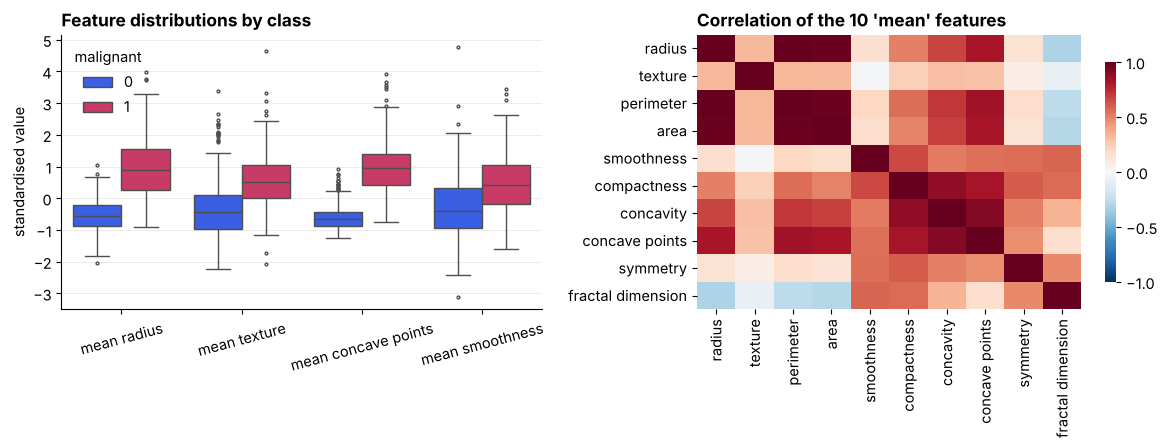

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
long = df.melt(id_vars="malignant", value_vars=["mean radius", "mean texture", "mean concave points", "mean smoothness"])
long["z"] = long.groupby("variable")["value"].transform(lambda s: (s - s.mean()) / s.std())
sns.boxplot(data=long, x="variable", y="z", hue="malignant", ax=axes[0], fliersize=2)
axes[0].set(xlabel="", ylabel="standardised value", title="Feature distributions by class")
axes[0].tick_params(axis="x", rotation=15)
corr = df.drop(columns="malignant").iloc[:, :10].corr()
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], cbar_kws={"shrink": 0.8},
            xticklabels=[c.replace("mean ", "") for c in corr.columns], yticklabels=[c.replace("mean ", "") for c in corr.columns])
axes[1].set_title("Correlation of the 10 'mean' features"); axes[1].grid(False)
plt.tight_layout()
plt.show()

## 29.5 Step 4: split and lock away the test set · *Beginner*

**Stratified hold-out split**

In [4]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="malignant")
y = df["malignant"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"train n={len(y_train)} ({y_train.mean():.1%} malignant) | test n={len(y_test)} ({y_test.mean():.1%} malignant)")

train n=426 (37.3% malignant) | test n=143 (37.1% malignant)


## 29.6 Steps 5–6: baselines and candidate models under repeated CV · *Intermediate*

**Compare candidates with identical, repeated CV**

In [5]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
candidates = {
    "Dummy": DummyClassifier(strategy="prior"),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC()),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "HistGB": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
scoring = {"auc": "roc_auc", "bal_acc": "balanced_accuracy", "recall": "recall"}
cv_scores, rows = {}, []
for name, est in candidates.items():
    r = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_scores[name] = r["test_auc"]
    rows.append({"model": name, **{f"{k} mean": r[f"test_{k}"].mean() for k in scoring},
                 "auc sd": r["test_auc"].std()})
summary = pd.DataFrame(rows).sort_values("auc mean", ascending=False).round(4)
print(summary.to_string(index=False))

       model  auc mean  bal_acc mean  recall mean  auc sd
      LogReg    0.9978        0.9726       0.9586  0.0026
     SVM-RBF    0.9969        0.9687       0.9486  0.0034
      HistGB    0.9944        0.9524       0.9310  0.0051
         kNN    0.9932        0.9553       0.9173  0.0070
RandomForest    0.9928        0.9558       0.9371  0.0084
       Dummy    0.5000        0.5000       0.0000  0.0000


**Show the spread, not just the mean**

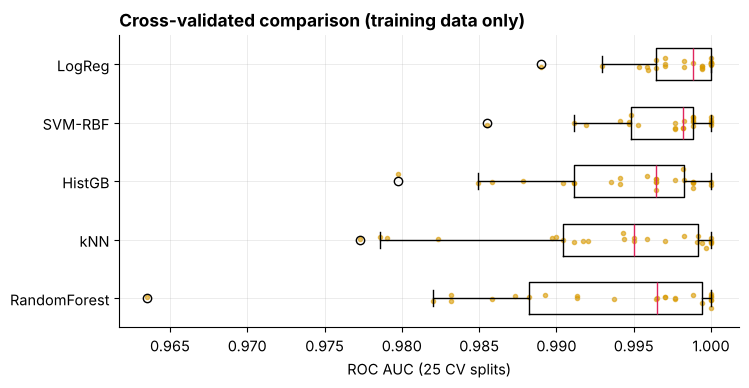

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = summary["model"].tolist()[::-1]
order = [m for m in order if m != "Dummy"]
ax.boxplot([cv_scores[m] for m in order], orientation="horizontal", tick_labels=order, widths=0.55)
for i, m in enumerate(order, start=1):
    ax.scatter(cv_scores[m], np.random.default_rng(i).normal(i, 0.06, len(cv_scores[m])), s=9, alpha=0.6, color="#d99a00")
ax.set(xlabel="ROC AUC (25 CV splits)", title="Cross-validated comparison (training data only)")
plt.show()

## 29.7 Step 7: tune the chosen model · *Intermediate*

**Grid search on training data**

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, solver="liblinear"))
grid = {"logisticregression__C": np.logspace(-3, 2, 11),
        "logisticregression__l1_ratio": [0.0, 1.0]}
search = GridSearchCV(pipe, grid, scoring="roc_auc",
                      cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
search.fit(X_train, y_train)
best_C = search.best_params_["logisticregression__C"]
print("best:", {"C": round(float(best_C), 4), "l1_ratio": search.best_params_["logisticregression__l1_ratio"]},
      "| CV AUC:", round(search.best_score_, 4))
final_model = search.best_estimator_

best: {'C': 1.0, 'l1_ratio': 1.0} | CV AUC: 0.9978


### 29.7.1 Choose the operating threshold on training data · *Intermediate*

**A threshold for ≥ 95% sensitivity, from out-of-fold predictions**

In [8]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(final_model, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                        method="predict_proba")[:, 1]
thresholds = np.linspace(0.01, 0.99, 99)
sens = np.array([((oof >= t) & (y_train == 1)).sum() / (y_train == 1).sum() for t in thresholds])
threshold = float(thresholds[sens >= 0.95].max())
print(f"chosen threshold = {threshold:.2f}")

chosen threshold = 0.63


## 29.8 Step 8: the one-time test evaluation · *Intermediate*

**Test metrics with bootstrap 95% confidence intervals**

In [9]:
from sklearn.metrics import roc_auc_score, recall_score, balanced_accuracy_score, brier_score_loss, confusion_matrix

p_test = final_model.predict_proba(X_test)[:, 1]
yhat = (p_test >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
metrics = {
    "ROC AUC": lambda yt, p, yh: roc_auc_score(yt, p),
    "Sensitivity": lambda yt, p, yh: recall_score(yt, yh),
    "Specificity": lambda yt, p, yh: recall_score(yt, yh, pos_label=0),
    "Balanced acc.": lambda yt, p, yh: balanced_accuracy_score(yt, yh),
    "Brier score": lambda yt, p, yh: brier_score_loss(yt, p),
}
rng = np.random.default_rng(RANDOM_STATE)
yt_arr = y_test.to_numpy()
boot = {k: [] for k in metrics}
for _ in range(2000):
    idx = rng.integers(0, len(yt_arr), len(yt_arr))
    if yt_arr[idx].min() == yt_arr[idx].max():
        continue
    for k, f in metrics.items():
        boot[k].append(f(yt_arr[idx], p_test[idx], yhat[idx]))
results = pd.DataFrame({k: {"estimate": f(yt_arr, p_test, yhat),
                            "95% CI low": np.percentile(boot[k], 2.5),
                            "95% CI high": np.percentile(boot[k], 97.5)} for k, f in metrics.items()}).T.round(3)
print(results)
print(f"confusion matrix: TN={tn} FP={fp} FN={fn} TP={tp}")

               estimate  95% CI low  95% CI high
ROC AUC           0.980       0.951        1.000
Sensitivity       0.906       0.816        0.980
Specificity       0.989       0.965        1.000
Balanced acc.     0.947       0.902        0.985
Brier score       0.032       0.011        0.059
confusion matrix: TN=89 FP=1 FN=5 TP=48


**Final figures for the paper**

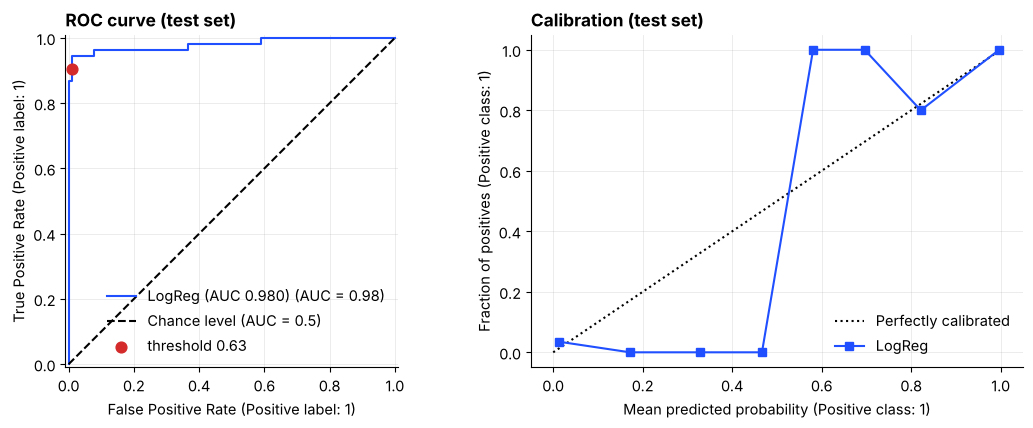

In [10]:
from sklearn.metrics import RocCurveDisplay
from sklearn.calibration import CalibrationDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[0], name=f"LogReg (AUC {roc_auc_score(y_test, p_test):.3f})",
                                 plot_chance_level=True)
axes[0].scatter(fp / (fp + tn), tp / (tp + fn), s=60, color="#d42a2a", zorder=5, label=f"threshold {threshold:.2f}")
axes[0].legend(loc="lower right"); axes[0].set_title("ROC curve (test set)")
CalibrationDisplay.from_predictions(y_test, p_test, n_bins=8, ax=axes[1], name="LogReg")
axes[1].set_title("Calibration (test set)")
plt.tight_layout()
plt.show()

## 29.9 Step 9: interpretation, with stability · *Intermediate*

**Permutation importance on the test set, and coefficient stability across CV folds**

In [11]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"drop in AUC": pi.importances_mean, "sd": pi.importances_std}, index=X.columns)
print(imp.sort_values("drop in AUC", ascending=False).head(6).round(4))

cvr = cross_validate(final_model, X_train, y_train, cv=cv, return_estimator=True, n_jobs=-1)
coefs = pd.DataFrame([e.named_steps["logisticregression"].coef_[0] for e in cvr["estimator"]], columns=X.columns)
stab = pd.DataFrame({"median coef": coefs.median(), "% non-zero": (coefs != 0).mean() * 100,
                     "% positive": (coefs > 0).mean() * 100})
print(stab.reindex(coefs.median().abs().sort_values(ascending=False).index).head(8).round(2))

                         drop in AUC      sd
worst area                    0.0698  0.0161
worst radius                  0.0139  0.0073
worst texture                 0.0114  0.0068
radius error                  0.0074  0.0021
mean concavity                0.0051  0.0045
fractal dimension error       0.0031  0.0033
                      median coef  % non-zero  % positive
worst area                   3.58        96.0        96.0
worst radius                 2.22       100.0       100.0
worst texture                1.72       100.0       100.0
worst smoothness             0.98       100.0       100.0
mean concavity               0.88        88.0        88.0
worst concavity              0.61        88.0        88.0
radius error                 0.58       100.0       100.0
worst concave points         0.54        88.0        88.0


## 29.10 Step 10: robustness checks · *Intermediate*

**Seed sensitivity and a learning curve**

In [12]:
from sklearn.model_selection import learning_curve
seed_aucs = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
    m = GridSearchCV(pipe, grid, scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=seed), n_jobs=-1).fit(Xa, ya)
    seed_aucs.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]))
print(f"test AUC over 10 different splits: mean={np.mean(seed_aucs):.4f}, SD={np.std(seed_aucs):.4f}, "
      f"range={min(seed_aucs):.4f}–{max(seed_aucs):.4f}")
sizes, tr_s, va_s = learning_curve(final_model, X_train, y_train, cv=5, scoring="roc_auc",
                                   train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1)
print("learning curve (validation AUC):", dict(zip(sizes.tolist(), va_s.mean(axis=1).round(4).tolist())))

test AUC over 10 different splits: mean=0.9919, SD=0.0072, range=0.9740–0.9990


learning curve (validation AUC): {68: 0.9971, 136: 0.9972, 204: 0.998, 272: 0.9979, 340: 0.9979}


## 29.11 Step 11: make it reproducible · *Beginner*

**Save the model, the configuration and the environment**

In [13]:
import json, joblib, sys, sklearn, platform
joblib.dump(final_model, "final_model.joblib")
run_record = {
    "random_state": RANDOM_STATE, "threshold": threshold,
    "best_params": {k: float(v) for k, v in search.best_params_.items()},
    "test_metrics": results["estimate"].to_dict(),
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
}
with open("run_record.json", "w") as f:
    json.dump(run_record, f, indent=2)
print(json.dumps(run_record, indent=2)[:600])

{
  "random_state": 2026,
  "threshold": 0.63,
  "best_params": {
    "logisticregression__C": 1.0,
    "logisticregression__l1_ratio": 1.0
  },
  "test_metrics": {
    "ROC AUC": 0.98,
    "Sensitivity": 0.906,
    "Specificity": 0.989,
    "Balanced acc.": 0.947,
    "Brier score": 0.032
  },
  "versions": {
    "python": "3.13.18",
    "numpy": "2.5.3",
    "pandas": "3.0.5",
    "scikit-learn": "1.9.1"
  }
}


## Try it yourself

1. Re-run the protocol with `HistGradientBoostingClassifier` as the primary model. Is the conclusion different?
2. Replace the hold-out test set by nested cross-validation (Chapter 23) and compare the estimates.
3. Write the Methods paragraph for this study using the checklist in Chapter 31.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 29*.